# Directional response

Synthetic data · linear classifier · Supplementary Note S2

In [1]:
from pathlib import Path
import sys
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/s2_direction.json').exists())
sys.path.insert(0, str(ROOT / 'src'))
from gw import direction_report
raw, summary = direction_report.recompute(ROOT)
from gw.publication_ui import folded_table, folded_comparison, compact_settings

## Results

100 paired seeds · 95% paired bootstrap CI · 10,000 resamples.

Δ compares the response along v after warm-up targeting v versus w; negative values indicate a lower response.

In [2]:
display(direction_report.table(summary).style.format({'Mean log difference Δ': '{:.4f}'}).set_properties(**{'padding': '10px 14px', 'font-size': '14px'}))

,Mean log difference Δ,95% CI,Lower response
Time,,,
After warm-up,-18.0194,"[-18.3141, -17.6635]",100/100
"Supervised step 1,000",-6.8921,"[-7.4078, -6.3411]",97/100


## Response

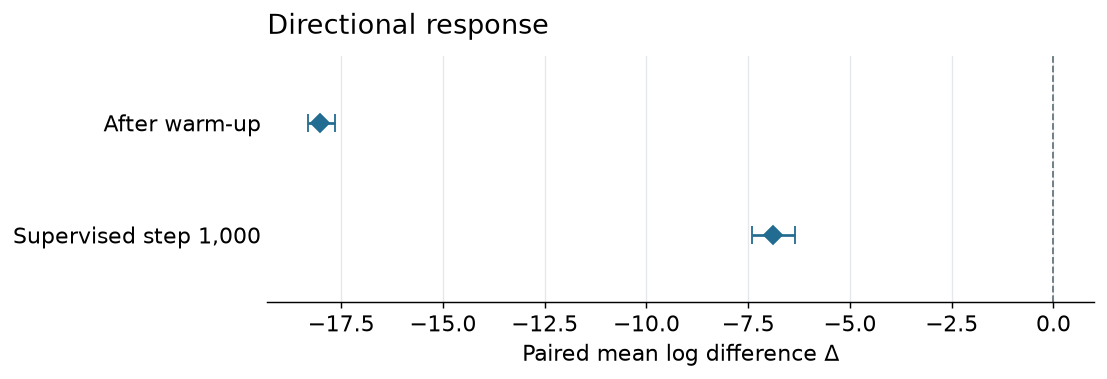

In [3]:
figure = direction_report.plot(summary, ROOT / 'assets/figures/s2_direction.png')
display(figure)
import matplotlib.pyplot as plt
plt.close(figure)

## Settings

8-dimensional inputs · warm-up: 500 steps · supervised training: 1,000 steps · ε = 10⁻¹².

<details><summary>Configuration</summary>

[Complete settings](../configs/s2_direction.json). Rankings use raw responses; log differences use R + ε.

</details>

## Reference values

Means, intervals and rankings are recalculated from saved paired responses.

In [4]:
check = direction_report.comparison(ROOT, summary)
assert check['Match'].all()
folded_comparison(check)

,Paper Δ,Recomputed Δ
Time,,
After warm-up,-18.0194,-18.0194
"Supervised step 1,000",-6.8921,-6.89213


## Run experiment

Optional: rerun the synthetic optimization experiment. New results are saved separately.

In [5]:
RUN_EXPERIMENT = False
if RUN_EXPERIMENT:
    from gw import direction_experiment
    from dataclasses import replace
    from datetime import datetime, timezone
    cfg = replace(direction_experiment.ExperimentConfig(), architectures=('linear',))
    destination = ROOT / 'output/s2_direction' / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
    result = direction_experiment.run_experiment(cfg, destination, 'formal:primary')
    print(f'Results: {destination}')